# Preguntas del taller 5

1. Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de promedio a una imagen. Los argumentos de
entrada son la imagen, la máscara y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a la
una imagen en escala de grises para las siguientes máscaras:
![Máscaras de filtros paso bajo](images/imgpt1.png)

2. Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de la media (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises.

3. Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de la mediana (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises. Usar cualquier imagen en
escala de grises.

4. Desarrollar una función basada en ciclos que permita aplicar
filtros paso alto con una máscara (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises.

5. Aplicar el filtro de la mediana a la imagen en escala de grises,
luego aplicar el filtro paso alto. Aparece la imagen
minimizada, pero con bordes bien definidos. Posteriormente,
aplicar al filtro paso alto a la imagen original y comparar los
resultados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

os.makedirs('results', exist_ok=True)

## Punto 1
Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de promedio a una imagen. Los argumentos de
entrada son la imagen, la máscara y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a la
una imagen en escala de grises para las siguientes máscaras:
![Máscaras de filtros paso bajo](images/imgpt1.png)


In [2]:
# mascaras

mascara1 = np.ones((3, 3))/9

mascara2 = np.ones((5, 5))/25

mascara3 = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])/16


def filtro_promedio(imagen, mascara):
    # Dimensiones imagen
    filas_imagen, columnas_imagen = imagen.shape
    # Dimensiones mascara
    filas_mascara, columnas_mascara = mascara.shape

    #extension de la mascara, por ejemplo, si la mascara es de 3x3, la extension es 1, si es de 5x5, la extension es 2
    extension_fila = filas_mascara // 2
    extension_columna = columnas_mascara // 2

    # Crear imagen de salida copia de la original, y no modificamos bordes, por eso se hace una copia de la imagen original
    imagen_filtrada = imagen.astype(np.float64).copy()

    # Recorrer cada pixel de la imagen
    for fila_imagen in range(extension_fila, filas_imagen - extension_fila):
        for columna_imagen in range(extension_columna, columnas_imagen - extension_columna):
            suma = 0 # la suma de los pixeles multiplicados por el peso de la mascara
            # Recorrer cada pixel de la mascara
            for fila_mascara in range(filas_mascara):
                for columna_mascara in range(columnas_mascara):
                    # obtenemos pixeles de la imagen, esto se hace sumando la posicion de la mascara a la posicion de la imagen, y restando la extension de la mascara
                    pixel = int(imagen[fila_imagen + fila_mascara - extension_fila, columna_imagen + columna_mascara - extension_columna])

                    # obtenemos el peso de la mascara, esto se hace obteniendo el valor de la mascara en la posicion de la mascara
                    peso = mascara[fila_mascara, columna_mascara]
                    suma += pixel * peso # multiplicamos el pixel por el peso de la mascara y lo sumamos a la suma total

            imagen_filtrada[fila_imagen, columna_imagen] = suma

    return np.clip(imagen_filtrada, 0, 255).astype(np.uint8)

Tamaño de la imagen: (533, 800)


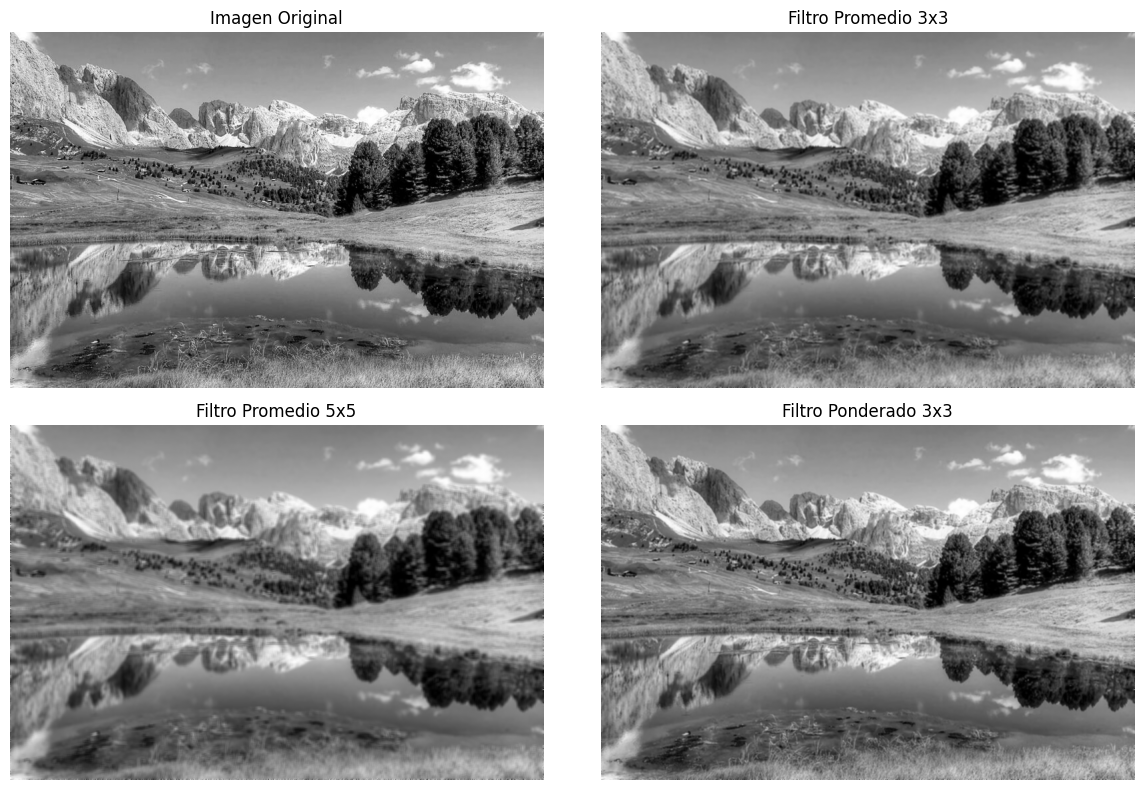

In [3]:
imagen = cv2.imread('images/paisaje.png', cv2.IMREAD_GRAYSCALE)

print("Tamaño de la imagen:", imagen.shape)

# Aplicar filtro promedio con mascara 1
imagen_filtrada1 = filtro_promedio(imagen, mascara1)
# Aplicar filtro promedio con mascara 2
imagen_filtrada2 = filtro_promedio(imagen, mascara2)
# Aplicar filtro promedio con mascara 3
imagen_filtrada3 = filtro_promedio(imagen, mascara3)

imagenes = [imagen, imagen_filtrada1, imagen_filtrada2, imagen_filtrada3]
titulos = ['Imagen Original', 'Filtro Promedio 3x3', 'Filtro Promedio 5x5', 'Filtro Ponderado 3x3']
# Mostrar imagen original y filtradas
fig, axs = plt.subplots(2,2, figsize=(12, 8))

for a, img, titulo in zip(axs.flat, imagenes, titulos):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(titulo)
    a.axis('off')

plt.tight_layout()
plt.savefig('results/resultado_filtro_promedio.png')
plt.show()



### Análisis de resultados — Punto 1

Se implementó una función de filtrado paso bajo utilizando ciclos for y se aplicaron tres máscaras sobre una imagen en escala de grises.

Al comparar los resultados, se observa que la máscara ponderada de 3×3 produce el menor suavizado y conserva mejor los detalles y bordes de las montañas, los árboles y sus reflejos en el agua.

Por otra parte, la máscara de promedio uniforme de 3×3 genera un suavizado mayor que la ponderada, haciendo que los bordes de los árboles y las montañas pierdan un poco más de definición. Finalmente, la máscara de 5×5 produce el desenfoque más evidente, con una mayor pérdida de detalles.

Estas diferencias se deben tanto al tamaño de la máscara como a la distribución de sus pesos. En la máscara ponderada, el píxel central tiene mayor importancia, por lo que se conservan mejor algunas características de la imagen original.

En conclusión, los filtros paso bajo reducen las variaciones de intensidad entre píxeles vecinos, produciendo un efecto de suavizado. Sin embargo, también pueden provocar una pérdida de detalles y definición de los bordes. En este caso, el filtro ponderado de 3×3 ofreció el mejor equilibrio entre suavizado y conservación de los detalles de la imagen.

## Punto2
Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de la media (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises.

In [4]:

# Funcion para aplicar filtro de media a una imagen
def filtro_media(imagen, tamano):
    if tamano % 2 == 0 or tamano < 1:
        raise ValueError("El tamaño de la máscara debe ser un número impar y mayor que 0.")
    # Dimensiones imagen
    filas_imagen, columnas_imagen = imagen.shape

    #extension de la mascara
    extension = tamano // 2

    # Copia imagen original
    imagen_filtrada = imagen.astype(np.float64).copy()

    # Recorrer cada pixel de la imagen
    for fila_imagen in range(extension, filas_imagen - extension):
        for columna_imagen in range(extension, columnas_imagen - extension):
            suma = 0 
            for i in range(-extension, extension + 1): # ej si es 3x3, extension = 1, entonces i va de -1 a 1
                for j in range(-extension, extension + 1):
                    pixel = int(imagen[fila_imagen + i, columna_imagen + j])
                    suma += pixel

            imagen_filtrada[fila_imagen, columna_imagen] = suma / (tamano * tamano)

    return np.clip(imagen_filtrada, 0, 255).astype(np.uint8)



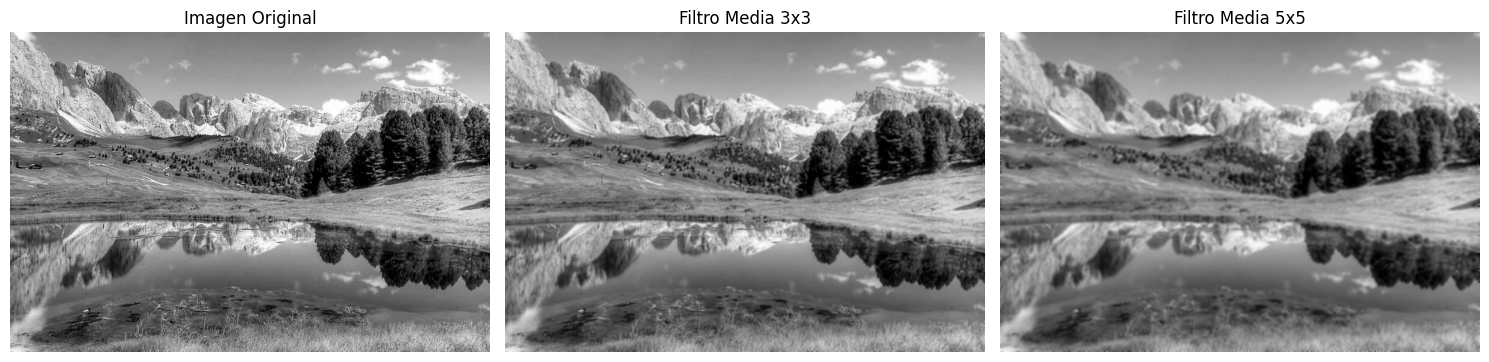

In [9]:

imagen = cv2.imread('images/paisaje.png', cv2.IMREAD_GRAYSCALE)

imagen_filtrada_3x3 = filtro_media(imagen, 3)
imagen_filtrada_5x5 = filtro_media(imagen, 5)

imagenes = [imagen, imagen_filtrada_3x3, imagen_filtrada_5x5]
titulos = ['Imagen Original', 'Filtro Media 3x3', 'Filtro Media 5x5']
# Mostrar imagen original y filtradas

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for a, img, titulo in zip(axs.flat, imagenes, titulos):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(titulo)
    a.axis('off')

plt.tight_layout()
plt.savefig('results/resultado_filtro_media.png')
plt.show()

### Análisis de resultados — Punto 2

Se implementó una función para aplicar filtros de media de 3×3 y 5×5 mediante ciclos `for`, calculando el promedio de los valores de los píxeles de cada vecindad.

Al observar los resultados, se evidencia que el filtro de media 3×3 produce un suavizado ligero, conservando gran parte de los detalles de las montañas, los árboles y sus reflejos en el agua.

Por otro lado, el filtro de media 5×5 genera un desenfoque mayor, haciendo que los bordes de las montañas, los árboles y algunos detalles de la vegetación pierdan más definición.

**En conclusión**, los filtros de media permiten suavizar una imagen al reducir las variaciones de intensidad entre píxeles vecinos. Se observa que, al aumentar el tamaño de la ventana, el suavizado es mayor, pero también se pierde más información de los detalles y bordes de la imagen.

## Punto 3
Desarrollar una función basada en ciclos que permita aplicar
filtros paso bajo de la mediana (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises. Usar cualquier imagen en
escala de grises.

In [6]:
def filtro_mediana(imagen, tamano):
    if tamano % 2 == 0 or tamano < 1:
        raise ValueError("El tamaño de la máscara debe ser un número impar y mayor que 0.")

    filas_imagen, columnas_imagen = imagen.shape

    # Calcular el radio de la máscara
    extension = tamano // 2

    # Copia de la imagen
    imagen_filtrada = imagen.copy()

    # Recorrer cada pixel de la imagen
    for fila_imagen in range(extension, filas_imagen - extension):
        for columna_imagen in range(extension, columnas_imagen - extension):
            #Extraer vecinos
            vecinos = []
            for i in range(-extension, extension + 1):
                for j in range(-extension, extension + 1):
                    pixel = int(imagen[fila_imagen + i, columna_imagen + j])
                    vecinos.append(pixel)

            # Calcular la mediana
            vecinos.sort()

            mediana = vecinos[len(vecinos) // 2]
            imagen_filtrada[fila_imagen, columna_imagen] = mediana

    return imagen_filtrada

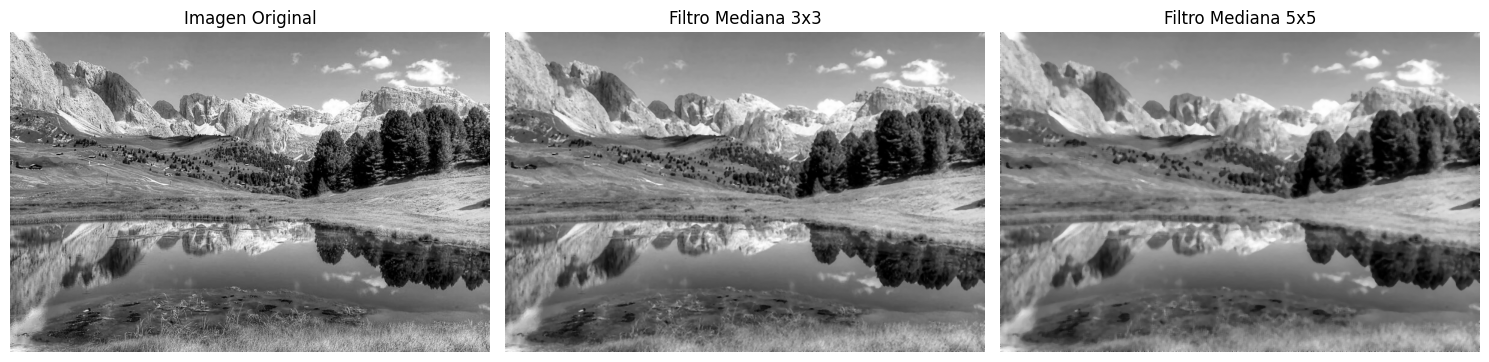

In [7]:
# Aplicar filtro de mediana 3x3
imagen_mediana3 = filtro_mediana(imagen, 3)

# Aplicar filtro de mediana 5x5
imagen_mediana5 = filtro_mediana(imagen, 5)

# Mostrar resultados
imagenes = [imagen, imagen_mediana3, imagen_mediana5]

titulos = [
    "Imagen Original",
    "Filtro Mediana 3x3",
    "Filtro Mediana 5x5"
]

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for ax, img, titulo in zip(axs, imagenes, titulos):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.savefig("results/resultado_filtro_mediana.png", dpi=150)
plt.show()

### Análisis de resultados — Punto 3

Se implementó una función para aplicar filtros de mediana de 3×3 y 5×5 mediante ciclos `for`, ordenando los valores de los píxeles de cada vecindad y seleccionando el valor central.

Al observar los resultados, se evidencia que el filtro de mediana 3×3 produce cambios leves en la imagen, conservando gran parte de los detalles y bordes de las montañas, los árboles y sus reflejos en el agua.

Por otra parte, el filtro de mediana 5×5 genera un suavizado mayor, eliminando algunos detalles pequeños de la vegetación y las texturas, pero manteniendo relativamente bien los contornos principales de los objetos.

Las diferencias respecto a la imagen original no son muy pronunciadas, debido a que la fotografía no presenta una cantidad evidente de ruido impulsivo.

**En conclusión**, el filtro de mediana permite suavizar la imagen y reducir valores de intensidad aislados, conservando relativamente bien los bordes. Al aumentar el tamaño de la ventana, se eliminan más detalles pequeños, por lo que es importante elegir el tamaño según las características de la imagen.

## Punto 4. 
Desarrollar una función basada en ciclos que permita aplicar
filtros paso alto con una máscara (3x3 y 5x5) a una imagen. El
argumento de entrada es la imagen y la salida es la imagen
filtrada. Observar los resultados obtenidos al aplicar el filtro a
una imagen en escala de grises.

In [13]:
def filtro_paso_alto(imagen,mascara):
    # Dimensiones imagen
    filas_imagen, columnas_imagen = imagen.shape
    # Dimensiones mascara
    filas_mascara, columnas_mascara = mascara.shape

    #extension de la mascara, por ejemplo, si la mascara es de 3x3, la extension es 1, si es de 5x5, la extension es 2
    extension_fila = filas_mascara // 2
    extension_columna = columnas_mascara // 2

    # Imagen se inicializa en 0 porque buscamos solo la respuesta pasa alto, y salida en float64 para evitar overflow, manejamos numeros negativos
    imagen_filtrada = np.zeros_like(imagen, dtype=np.float64)


    # Recorrer cada pixel de la imagen
    for fila_imagen in range(extension_fila, filas_imagen - extension_fila):
        for columna_imagen in range(extension_columna, columnas_imagen - extension_columna):
            suma = 0 # la suma de los pixeles multiplicados por el peso de la mascara
            # Recorrer cada pixel de la mascara
            for fila_mascara in range(filas_mascara):
                for columna_mascara in range(columnas_mascara):
                    # obtenemos pixeles de la imagen, esto se hace sumando la posicion de la mascara a la posicion de la imagen, y restando la extension de la mascara
                    pixel = float(imagen[fila_imagen + fila_mascara - extension_fila, columna_imagen + columna_mascara - extension_columna])

                    # obtenemos el peso de la mascara, esto se hace obteniendo el valor de la mascara en la posicion de la mascara
                    peso = mascara[fila_mascara, columna_mascara]
                    suma += pixel * peso # multiplicamos el pixel por el peso de la mascara y lo sumamos a la suma total

            imagen_filtrada[fila_imagen, columna_imagen] = suma

    return imagen_filtrada

In [15]:
mascara_alto3 = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

mascara_alto5 = -np.ones((5, 5))
mascara_alto5[2, 2] = 24


imagen_alto3 = filtro_paso_alto(imagen, mascara_alto3)
imagen_alto5 = filtro_paso_alto(imagen, mascara_alto5)

imagen_alto3_visual = np.clip(
    np.abs(imagen_alto3), 0, 255
).astype(np.uint8)

imagen_alto5_visual = np.clip(
    np.abs(imagen_alto5), 0, 255
).astype(np.uint8)

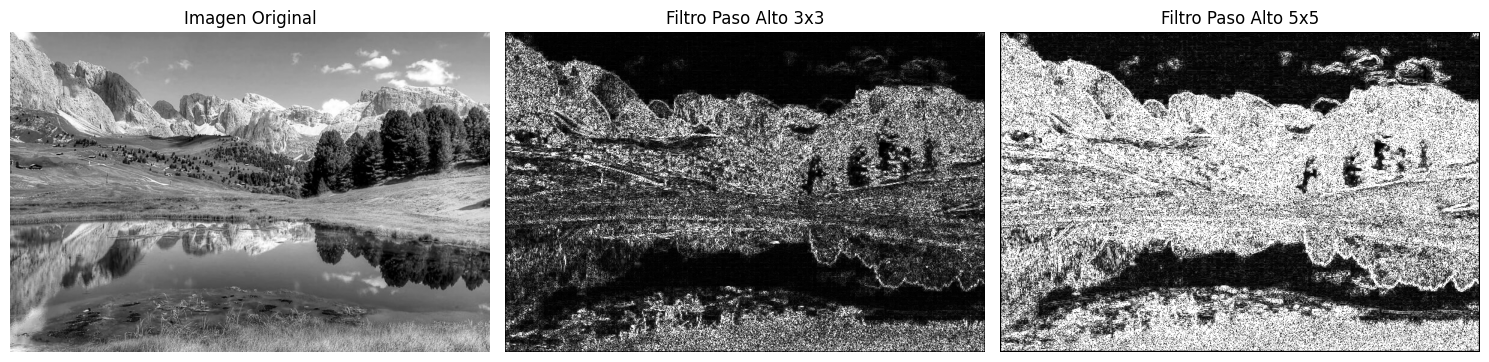

In [23]:
imagenes = [
    imagen,
    imagen_alto3_visual,
    imagen_alto5_visual
]

titulos = [
    "Imagen Original",
    "Filtro Paso Alto 3x3",
    "Filtro Paso Alto 5x5"
]

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for ax, img, titulo in zip(axs, imagenes, titulos):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.savefig("results/resultado_filtro_paso_alto.png", dpi=150)
plt.show()

In [24]:
print("Respuesta máxima absoluta 3x3:",
      np.abs(imagen_alto3).max())

print("Respuesta máxima absoluta 5x5:",
      np.abs(imagen_alto5).max())

print("Píxeles saturados 3x3:",
      np.count_nonzero(np.abs(imagen_alto3) > 255))

print("Píxeles saturados 5x5:",
      np.count_nonzero(np.abs(imagen_alto5) > 255))

Respuesta máxima absoluta 3x3: 1214.0
Respuesta máxima absoluta 5x5: 3802.0
Píxeles saturados 3x3: 21808
Píxeles saturados 5x5: 152985


### Análisis de resultados — Punto 4

Se implementó una función para aplicar filtros paso alto con máscaras de 3×3 y 5×5 mediante ciclos for, multiplicando los valores de los píxeles por los coeficientes de cada máscara y sumando los resultados.

Al observar las imágenes obtenidas, se evidencia que el filtro paso alto 3×3 destaca los bordes de las montañas, los árboles y algunas texturas de la vegetación. Por otra parte, las regiones más uniformes, como el cielo y algunas zonas del agua, aparecen oscuras debido a que presentan pocas variaciones de intensidad.

En el filtro paso alto 5×5 se observa una respuesta mucho más intensa, especialmente en las montañas, los árboles y el pasto. Esto se debe a que la máscara considera una vecindad mayor y utiliza coeficientes que pueden generar valores de mayor magnitud.

También se observa que algunas regiones aparecen casi completamente blancas, debido a que los valores que superan 255 se limitan a ese máximo durante la visualización.

En conclusión, los filtros paso alto permiten destacar los cambios bruscos de intensidad, haciendo más visibles los bordes y las texturas de la imagen. Sin embargo, la intensidad de los resultados depende de los coeficientes de la máscara y de la forma en que se visualizan los valores obtenidos.

Al analizar los valores obtenidos, se encontró que el filtro paso alto 3×3 produjo una respuesta máxima absoluta de 1.214 y 21.808 píxeles con magnitudes superiores a 255. Por su parte, el filtro 5×5 alcanzó una respuesta máxima absoluta de 3.802 y 152.985 píxeles superiores a ese límite.

Esto explica por qué la imagen filtrada con la máscara 5×5 presenta una mayor cantidad de regiones blancas. Al limitar los valores al rango de 0 a 255 para visualizarlos, las respuestas más intensas se saturan y dejan de distinguirse entre sí.

Por tanto, una mayor intensidad visual no significa necesariamente una mejor detección de bordes, ya que también depende de los coeficientes de la máscara y del tratamiento aplicado a los resultados.